In [1]:
#!/usr/bin/env python3
import sys
import os
sys.path.append(os.path.join(os.path.dirname(os.getcwd())))

In [2]:
from src.paramertrized_circuit import ParametrizedCircuit

num_qubits = 2
depth = 1

Total theta params (Universal): 12


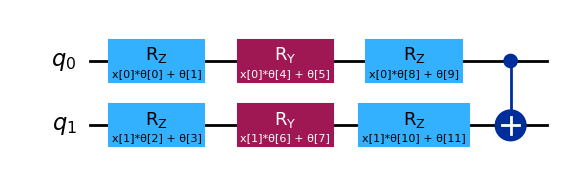

In [3]:
parm_circuit2 = ParametrizedCircuit.Universal_circuit(num_qubits, depth)
# set title
parm_circuit2.draw('mpl')

Total theta params (RealAmplitudes): 8


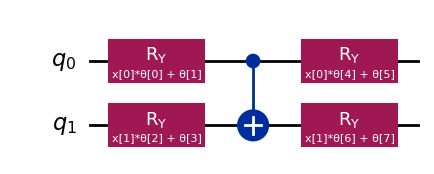

In [4]:
parm_circuit3 = ParametrizedCircuit.RealAmplitudes_circuit(num_qubits, depth)
parm_circuit3.draw('mpl')

Total theta params for EfficientSU2: 16


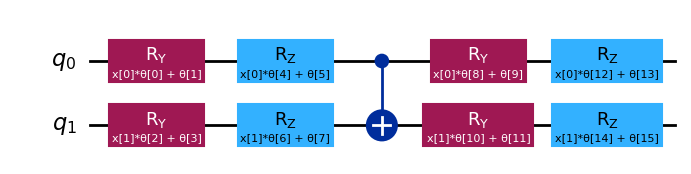

In [5]:
parm_circuit4 = ParametrizedCircuit.EfficientSU2_circuit(num_qubits, depth)
parm_circuit4.draw('mpl')

<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:34: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\p'
<>:36: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:34: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\p'
<>:36: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Nguyen Dinh Quyen\AppData\Local\Temp\ipykernel_22244\2731373434.py:15: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_title("Original Input Space $\mathcal{X} \subset \mathbb{R}^2$", fontsize=14, pad=15)
C:\Users\Nguyen Dinh Quyen\AppData\Local\Temp\ipykernel_22244\2731373434.py:34: SyntaxWarning: invalid escape sequence '\m'
  ax2.set_title("Feature Space $\mathcal{F} \subset \mathbb{R}^3$ via Feature Map $\phi(\mathbf{x})$", fontsize=14, pad=15)
C:\Users\Nguyen Dinh Q

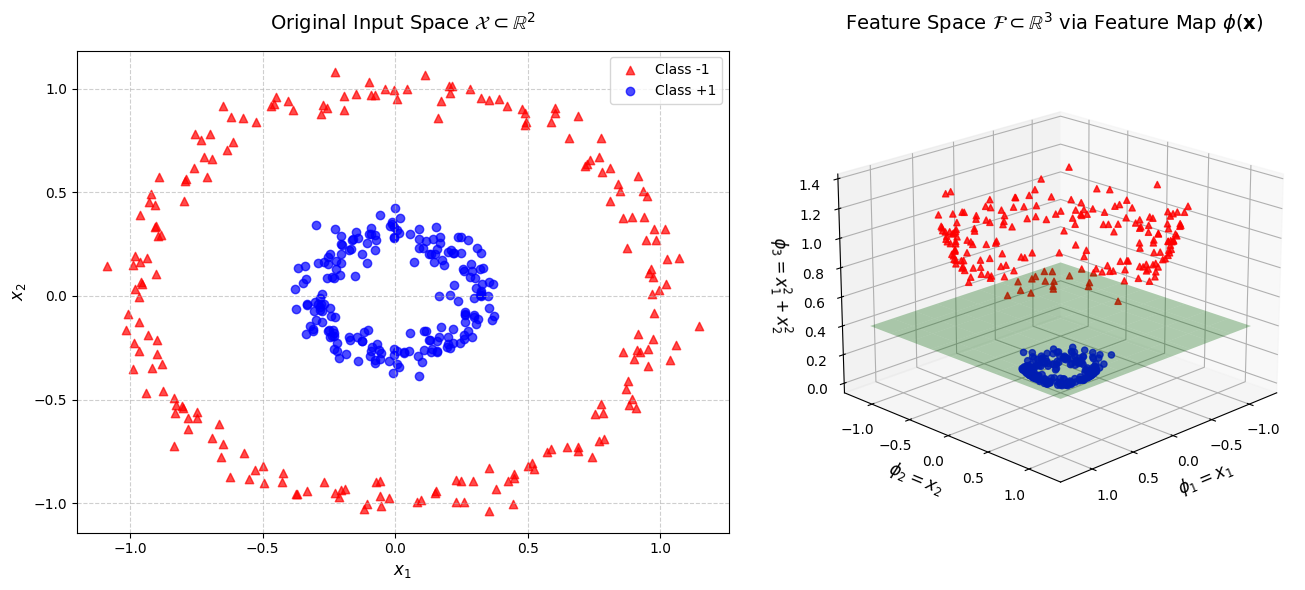

Đã lưu thành công file kernel_trick.png!


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

# 1. Tạo dữ liệu 2D (Hai vòng tròn lồng nhau, không thể phân tách tuyến tính)
X, y = make_circles(n_samples=400, factor=0.3, noise=0.05, random_state=42)

# 2. Setup khung hình
fig = plt.figure(figsize=(14, 6))

# ----- HÌNH BÊN TRÁI: KHÔNG GIAN 2D BAN ĐẦU -----
ax1 = fig.add_subplot(121)
ax1.scatter(X[y==0, 0], X[y==0, 1], color='red', marker='^', alpha=0.7, label='Class -1')
ax1.scatter(X[y==1, 0], X[y==1, 1], color='blue', marker='o', alpha=0.7, label='Class +1')
ax1.set_title("Original Input Space $\mathcal{X} \subset \mathbb{R}^2$", fontsize=14, pad=15)
ax1.set_xlabel("$x_1$", fontsize=12)
ax1.set_ylabel("$x_2$", fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# ----- HÌNH BÊN PHẢI: KHÔNG GIAN 3D (FEATURE SPACE) -----
# Ánh xạ lên chiều thứ 3: z = x1^2 + x2^2
Z = X[:, 0]**2 + X[:, 1]**2

ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(X[y==0, 0], X[y==0, 1], Z[y==0], color='red', marker='^', alpha=0.8)
ax2.scatter(X[y==1, 0], X[y==1, 1], Z[y==1], color='blue', marker='o', alpha=0.8)

# Vẽ mặt phẳng cắt ngang (Hyperplane) để chia tách 2 class
xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 10), np.linspace(-1.2, 1.2, 10))
zz = np.full(xx.shape, 0.4) # Mặt phẳng cắt ở z = 0.4
ax2.plot_surface(xx, yy, zz, alpha=0.3, color='green')

ax2.set_title("Feature Space $\mathcal{F} \subset \mathbb{R}^3$ via Feature Map $\phi(\mathbf{x})$", fontsize=14, pad=15)
ax2.set_xlabel("$\phi_1 = x_1$", fontsize=12)
ax2.set_ylabel("$\phi_2 = x_2$", fontsize=12)
ax2.set_zlabel("$\phi_3 = x_1^2 + x_2^2$", fontsize=12)

# Góc nhìn 3D đẹp nhất
ax2.view_init(elev=20, azim=45)

# 3. Lưu ảnh ra file để chèn vào LaTeX
plt.tight_layout()
plt.savefig("kernel_trick.png", dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu thành công file kernel_trick.png!")